# 09 — Explicabilidade (OE4)

**Dissertação:** Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora:** Luana Gomes de Souza — PPGI/UTFPR  
**Objetivo Específico:** OE4 — Investigar a explicabilidade das previsões

Este notebook aplica **SHAP** e **LIME** aos algoritmos comparados, investigando três questões (Seção 4.6 da dissertação):

1. As atribuições de importância são **consistentes entre janelas** de avaliação?
2. As features identificadas são **coerentes com o domínio** (lags sazonais dominantes)?
3. As atribuições se **mantêm estáveis** quando os dados sofrem perturbação adversa?

### Modelos analisados
| Família | Modelos | SHAP | LIME |
|---------|---------|------|------|
| Árvores | RandomForest, GradientBoosting | TreeExplainer (nativo) | ✓ |
| Suporte vetorial | SVR | KernelExplainer (amostrado) | ✓ |
| Suavização | HoltWinters, SES | Interpretabilidade intrínseca | — |

> Resultados salvos em `results/explicabilidade/`

## 0. Imports e configuração

In [1]:
import warnings, time, os, json
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path

# Modelos
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

# Explicabilidade
try:
    import shap
    print(f'SHAP versão: {shap.__version__}')
except ImportError:
    print('Instalando SHAP...')
    os.system('pip install shap -q')
    import shap

try:
    import lime
    from lime.lime_tabular import LimeTabularExplainer
    print(f'LIME instalado.')
except ImportError:
    print('Instalando LIME...')
    os.system('pip install lime -q')
    from lime.lime_tabular import LimeTabularExplainer

# ── Configuração padrão (idêntica aos notebooks 01-08) ────────────────────────
SEED      = 42
N_SERIES  = 200
H         = 18
MIN_TRAIN = 24
N_ORIGINS = 3
N_LAGS    = 12
SEASON    = 12

DATA_DIR  = Path('../data/raw')
RES_DIR   = Path('../results')
EXPL_DIR  = RES_DIR / 'explicabilidade'
EXPL_DIR.mkdir(parents=True, exist_ok=True)

# Subconjunto para análise de explicabilidade (30 séries = rápido + representativo)
N_EXPL    = 30

# Paleta consistente com notebooks anteriores
ALGO_COLORS = {
    'RandomForest'    : '#F44336',
    'GradientBoosting': '#9C27B0',
    'SVR'             : '#795548',
}

print(f'Diretório de explicabilidade: {EXPL_DIR.resolve()}')
print(f'Séries para explicabilidade: {N_EXPL} (subconjunto das 200 do piloto)')

Instalando SHAP...
Instalando LIME...
Diretório de explicabilidade: C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results\explicabilidade
Séries para explicabilidade: 30 (subconjunto das 200 do piloto)


## 1. Carga das séries piloto

In [2]:
train_raw = pd.read_csv(DATA_DIR / 'Monthly-train.csv', header=0, index_col=0)
test_raw  = pd.read_csv(DATA_DIR / 'Monthly-test.csv',  header=0, index_col=0)

# Mesmas 200 séries do piloto
rng_sel = np.random.default_rng(SEED)
idx_sel = rng_sel.choice(len(train_raw), size=N_SERIES, replace=False)

def parse_series(row):
    return row.dropna().values.astype(float)

series_list = [parse_series(train_raw.iloc[i]) for i in idx_sel]

# Subconjunto fixo para explicabilidade (seed separado para reprodutibilidade)
rng_expl  = np.random.default_rng(SEED + 1)
expl_idx  = rng_expl.choice(N_SERIES, size=N_EXPL, replace=False)
expl_series = [series_list[i] for i in expl_idx]

print(f'Séries piloto carregadas: {N_SERIES}')
print(f'Subconjunto para explicabilidade: {N_EXPL} séries')
print(f'Comprimento mediano: {np.median([len(s) for s in expl_series]):.0f} observações')

Séries piloto carregadas: 200
Subconjunto para explicabilidade: 30 séries
Comprimento mediano: 205 observações


## 2. Utilitários compartilhados

In [3]:
def build_features(series, n_lags=N_LAGS, season=SEASON):
    """Engenharia de features idêntica aos notebooks 05-08."""
    df = pd.DataFrame({'y': series})
    feat_cols = []
    for lag in range(1, n_lags + 1):
        col = f'lag_{lag}'
        df[col] = df['y'].shift(lag)
        feat_cols.append(col)
    for w, name in [(3, 'roll_mean_3'), (3, 'roll_std_3'), (6, 'roll_mean_6')]:
        if 'std' in name:
            df[name] = df['y'].shift(1).rolling(w).std()
        else:
            df[name] = df['y'].shift(1).rolling(w).mean()
        feat_cols.append(name)
    df['lag_season']  = df['y'].shift(season)
    df['lag_season2'] = df['y'].shift(season * 2)
    feat_cols += ['lag_season', 'lag_season2']
    df.dropna(inplace=True)
    X = df[feat_cols].values
    y = df['y'].values
    return X, y, feat_cols

def get_feature_names():
    """Retorna lista de nomes de features na ordem usada em build_features."""
    names = [f'lag_{i}' for i in range(1, N_LAGS + 1)]
    names += ['roll_mean_3', 'roll_std_3', 'roll_mean_6']
    names += ['lag_season', 'lag_season2']
    return names

FEATURE_NAMES = get_feature_names()
N_FEATURES    = len(FEATURE_NAMES)
print(f'Features ({N_FEATURES}): {FEATURE_NAMES}')

Features (17): ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12', 'roll_mean_3', 'roll_std_3', 'roll_mean_6', 'lag_season', 'lag_season2']


## 3. Treino dos modelos por série

Para cada série do subconjunto, treina RF, GB e SVR na janela de treino mais longa disponível.  
Guarda o modelo treinado e os dados de treino para uso pelo SHAP e LIME.

In [4]:
def train_models_for_series(series):
    """
    Treina RF, GB e SVR na janela completa de treino.
    Retorna dict com modelo, scaler (SVR), X_train, y_train, feature_names.
    """
    # Usa a janela de treino mais longa (exclui último H para teste)
    train = series[:-H] if len(series) > MIN_TRAIN + H else series
    X, y, feat_cols = build_features(train)

    if len(X) < 10:
        return None

    fitted = {}

    # Random Forest
    rf = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
    rf.fit(X, y)
    fitted['RandomForest'] = {'model': rf, 'X': X, 'y': y,
                               'scaler_X': None, 'scaler_y': None}

    # Gradient Boosting
    gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1,
                                    max_depth=3, random_state=SEED)
    gb.fit(X, y)
    fitted['GradientBoosting'] = {'model': gb, 'X': X, 'y': y,
                                   'scaler_X': None, 'scaler_y': None}

    # SVR (com normalização)
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    Xs = scaler_X.fit_transform(X)
    ys = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()
    svr = SVR(kernel='rbf', C=1.0, epsilon=0.1)
    svr.fit(Xs, ys)
    fitted['SVR'] = {'model': svr, 'X': X, 'y': y,
                     'scaler_X': scaler_X, 'scaler_y': scaler_y}

    return fitted


print('Treinando modelos para as séries de explicabilidade...')
t0 = time.time()
fitted_all = []
for i, s in enumerate(expl_series):
    res = train_models_for_series(s)
    fitted_all.append(res)
    if (i + 1) % 10 == 0:
        print(f'  {i+1}/{N_EXPL} séries treinadas')

validos = sum(1 for r in fitted_all if r is not None)
print(f'\n✓ Treino concluído em {time.time()-t0:.1f}s — {validos}/{N_EXPL} séries válidas')

Treinando modelos para as séries de explicabilidade...
  10/30 séries treinadas
  20/30 séries treinadas
  30/30 séries treinadas

✓ Treino concluído em 4.7s — 30/30 séries válidas


## 4. SHAP — Importância global e local

- **RandomForest / GradientBoosting** → `TreeExplainer` (exato, rápido)
- **SVR** → `KernelExplainer` (amostrado, mais lento)

In [5]:
SHAP_FILE = EXPL_DIR / 'shap_importancias.csv'

def compute_shap(fitted_dict, model_name, max_background=50):
    """
    Calcula valores SHAP para um modelo e retorna importâncias médias absolutas.
    """
    m   = fitted_dict['model']
    X   = fitted_dict['X']
    sX  = fitted_dict['scaler_X']

    X_input = sX.transform(X) if sX is not None else X

    # Limita background para velocidade
    bg_size = min(max_background, len(X_input))
    rng_bg  = np.random.default_rng(SEED)
    bg_idx  = rng_bg.choice(len(X_input), size=bg_size, replace=False)
    background = X_input[bg_idx]

    try:
        if model_name in ('RandomForest', 'GradientBoosting'):
            explainer   = shap.TreeExplainer(m)
            shap_values = explainer.shap_values(X_input)
        else:  # SVR
            explainer   = shap.KernelExplainer(m.predict, background)
            # Usa amostra menor para SVR (lento)
            sample_idx  = rng_bg.choice(len(X_input),
                                        size=min(30, len(X_input)), replace=False)
            shap_values = explainer.shap_values(X_input[sample_idx], nsamples=50)

        mean_abs = np.abs(shap_values).mean(axis=0)
        return mean_abs
    except Exception as e:
        return np.full(N_FEATURES, np.nan)


if SHAP_FILE.exists():
    df_shap = pd.read_csv(SHAP_FILE)
    print(f'SHAP carregado de cache: {SHAP_FILE}')
else:
    print('Calculando SHAP (pode levar alguns minutos para o SVR)...')
    shap_rows = []
    for i, fitted_dict in enumerate(fitted_all):
        if fitted_dict is None:
            continue
        if (i + 1) % 10 == 0:
            print(f'  SHAP: série {i+1}/{N_EXPL}')
        for model_name in ['RandomForest', 'GradientBoosting', 'SVR']:
            imp = compute_shap(fitted_dict[model_name], model_name)
            row = {'serie': i, 'modelo': model_name}
            for j, fname in enumerate(FEATURE_NAMES):
                row[fname] = imp[j] if j < len(imp) else np.nan
            shap_rows.append(row)

    df_shap = pd.DataFrame(shap_rows)
    df_shap.to_csv(SHAP_FILE, index=False)
    print(f'✓ SHAP salvo em {SHAP_FILE}')

print(f'Shape df_shap: {df_shap.shape}')
df_shap.head(3)

Calculando SHAP (pode levar alguns minutos para o SVR)...


100%|██████████| 30/30 [00:00<00:00, 45.94it/s]


  SHAP: série 10/30


100%|██████████| 30/30 [00:00<00:00, 107.36it/s]


  SHAP: série 20/30


100%|██████████| 30/30 [00:00<00:00, 73.64it/s]


  SHAP: série 30/30


100%|██████████| 30/30 [00:00<00:00, 157.70it/s]

✓ SHAP salvo em ..\results\explicabilidade\shap_importancias.csv
Shape df_shap: (90, 19)


,serie,modelo,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,roll_mean_3,roll_std_3,roll_mean_6,lag_season,lag_season2
0,0,RandomForest,57.491566,20.534849,18.611976,21.897253,12.335527,17.136044,13.036809,8.163693,15.678702,13.467898,11.213500,12.328242,25.820377,4.245718,9.940956,20.647729,5.449797
1,0,GradientBoosting,53.566291,66.259047,38.176148,29.142127,25.773938,5.403120,3.148015,9.787953,6.264694,9.381533,12.886429,8.607279,12.736769,9.322452,16.919075,9.791658,7.607716
2,0,SVR,0.101447,0.058420,0.059992,0.063272,0.037827,0.013233,0.030992,0.039400,0.047897,0.062871,0.054023,0.041657,0.056227,0.022666,0.055362,0.044849,0.022956


## 5. LIME — Explicações locais

Para cada série, gera explicação LIME para a **última observação do treino** (ponto de previsão).  
Registra os coeficientes do modelo substituto linear local.

In [6]:
LIME_FILE = EXPL_DIR / 'lime_importancias.csv'

def compute_lime(fitted_dict, model_name, feature_names):
    """
    Gera explicação LIME para o último ponto de treino.
    Retorna array de importâncias absolutas ordenado por feature.
    """
    m  = fitted_dict['model']
    X  = fitted_dict['X']
    sX = fitted_dict['scaler_X']
    sy = fitted_dict['scaler_y']

    X_input = sX.transform(X) if sX is not None else X

    def predict_fn(x):
        if sy is not None:
            return sy.inverse_transform(
                m.predict(x).reshape(-1, 1)
            ).ravel()
        return m.predict(x)

    try:
        explainer = LimeTabularExplainer(
            training_data  = X_input,
            feature_names  = feature_names,
            mode           = 'regression',
            random_state   = SEED,
            verbose        = False,
        )
        # Explica o último ponto de treino
        exp = explainer.explain_instance(
            X_input[-1],
            predict_fn,
            num_features = len(feature_names),
            num_samples  = 200,
        )
        # Monta vetor de coeficientes na ordem das features
        coef_dict = dict(exp.as_list())
        coefs = np.zeros(len(feature_names))
        for fname, val in coef_dict.items():
            # LIME inclui condições no nome (e.g. 'lag_1 > 0.5'), extrai nome base
            for j, fn in enumerate(feature_names):
                if fn in fname:
                    coefs[j] += abs(val)
                    break
        return coefs
    except Exception:
        return np.full(len(feature_names), np.nan)


if LIME_FILE.exists():
    df_lime = pd.read_csv(LIME_FILE)
    print(f'LIME carregado de cache: {LIME_FILE}')
else:
    print('Calculando LIME...')
    lime_rows = []
    for i, fitted_dict in enumerate(fitted_all):
        if fitted_dict is None:
            continue
        if (i + 1) % 10 == 0:
            print(f'  LIME: série {i+1}/{N_EXPL}')
        for model_name in ['RandomForest', 'GradientBoosting', 'SVR']:
            imp = compute_lime(fitted_dict[model_name], model_name, FEATURE_NAMES)
            row = {'serie': i, 'modelo': model_name}
            for j, fname in enumerate(FEATURE_NAMES):
                row[fname] = imp[j]
            lime_rows.append(row)

    df_lime = pd.DataFrame(lime_rows)
    df_lime.to_csv(LIME_FILE, index=False)
    print(f'✓ LIME salvo em {LIME_FILE}')

print(f'Shape df_lime: {df_lime.shape}')

Calculando LIME...
  LIME: série 10/30
  LIME: série 20/30
  LIME: série 30/30
✓ LIME salvo em ..\results\explicabilidade\lime_importancias.csv
Shape df_lime: (90, 19)


## 6. Visualizações SHAP

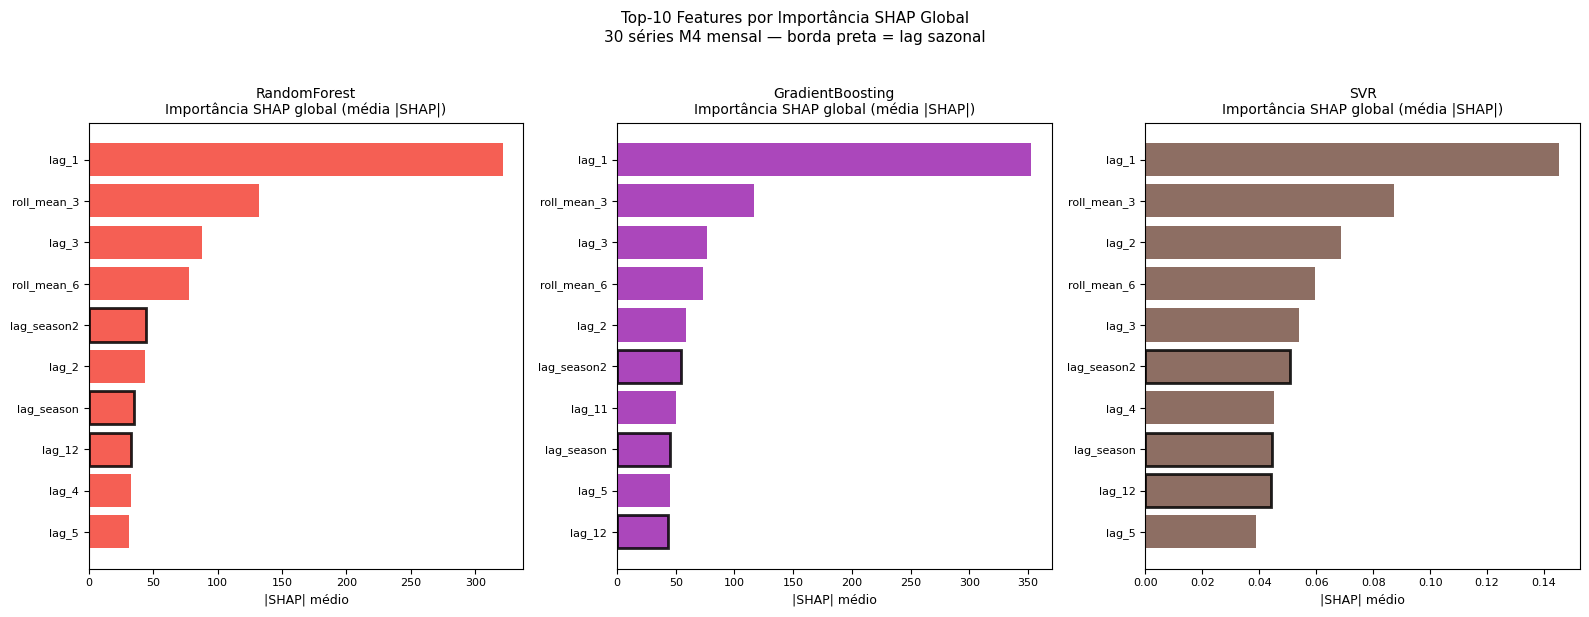

Fig 1 salva.


In [7]:
# ── Fig 1: Importância SHAP global por modelo (top-10 features) ───────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for ax, model_name in zip(axes, ['RandomForest', 'GradientBoosting', 'SVR']):
    sub  = df_shap[df_shap['modelo'] == model_name][FEATURE_NAMES]
    mean_imp = sub.mean().sort_values(ascending=False)
    top10    = mean_imp.head(10)

    color = ALGO_COLORS.get(model_name, 'steelblue')
    bars  = ax.barh(top10.index[::-1], top10.values[::-1], color=color, alpha=0.85)

    # Destaca lag sazonal
    for bar, lbl in zip(bars, top10.index[::-1]):
        if 'season' in lbl or lbl == 'lag_12':
            bar.set_edgecolor('black')
            bar.set_linewidth(2)

    ax.set_title(f'{model_name}\nImportância SHAP global (média |SHAP|)', fontsize=10)
    ax.set_xlabel('|SHAP| médio', fontsize=9)
    ax.tick_params(labelsize=8)

fig.suptitle('Top-10 Features por Importância SHAP Global\n'
             f'{N_EXPL} séries M4 mensal — borda preta = lag sazonal',
             fontsize=11, y=1.02)
plt.tight_layout()
fig.savefig(EXPL_DIR / 'fig1_shap_global.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 1 salva.')

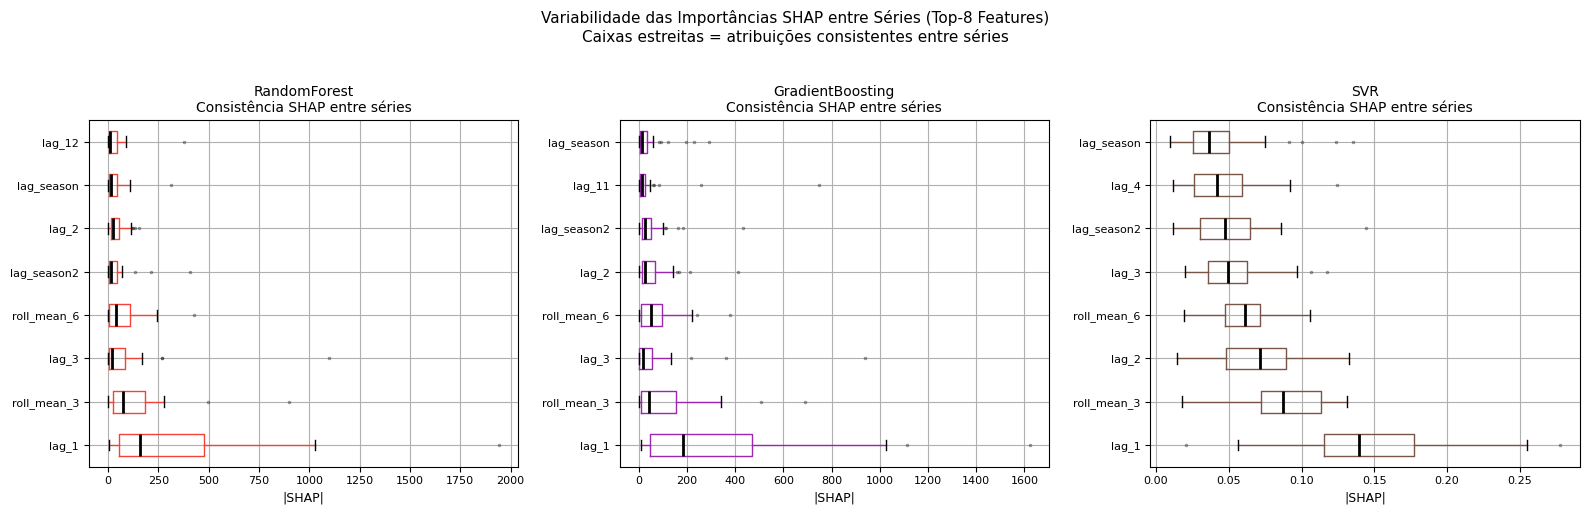

Fig 2 salva.


In [8]:
# ── Fig 2: Consistência SHAP entre séries (boxplot por feature, top-8) ────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, model_name in zip(axes, ['RandomForest', 'GradientBoosting', 'SVR']):
    sub      = df_shap[df_shap['modelo'] == model_name][FEATURE_NAMES]
    mean_imp = sub.mean().sort_values(ascending=False)
    top8     = mean_imp.head(8).index.tolist()
    data_plot = sub[top8]

    color = ALGO_COLORS.get(model_name, 'steelblue')
    data_plot.boxplot(
        ax=ax, vert=False,
        boxprops    = dict(color=color),
        whiskerprops= dict(color=color),
        medianprops = dict(color='black', linewidth=2),
        flierprops  = dict(marker='.', markersize=3, alpha=0.4),
    )
    ax.set_title(f'{model_name}\nConsistência SHAP entre séries', fontsize=10)
    ax.set_xlabel('|SHAP|', fontsize=9)
    ax.tick_params(labelsize=8)

fig.suptitle('Variabilidade das Importâncias SHAP entre Séries (Top-8 Features)\n'
             'Caixas estreitas = atribuições consistentes entre séries',
             fontsize=11, y=1.02)
plt.tight_layout()
fig.savefig(EXPL_DIR / 'fig2_shap_consistencia.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 2 salva.')

## 7. Visualizações LIME

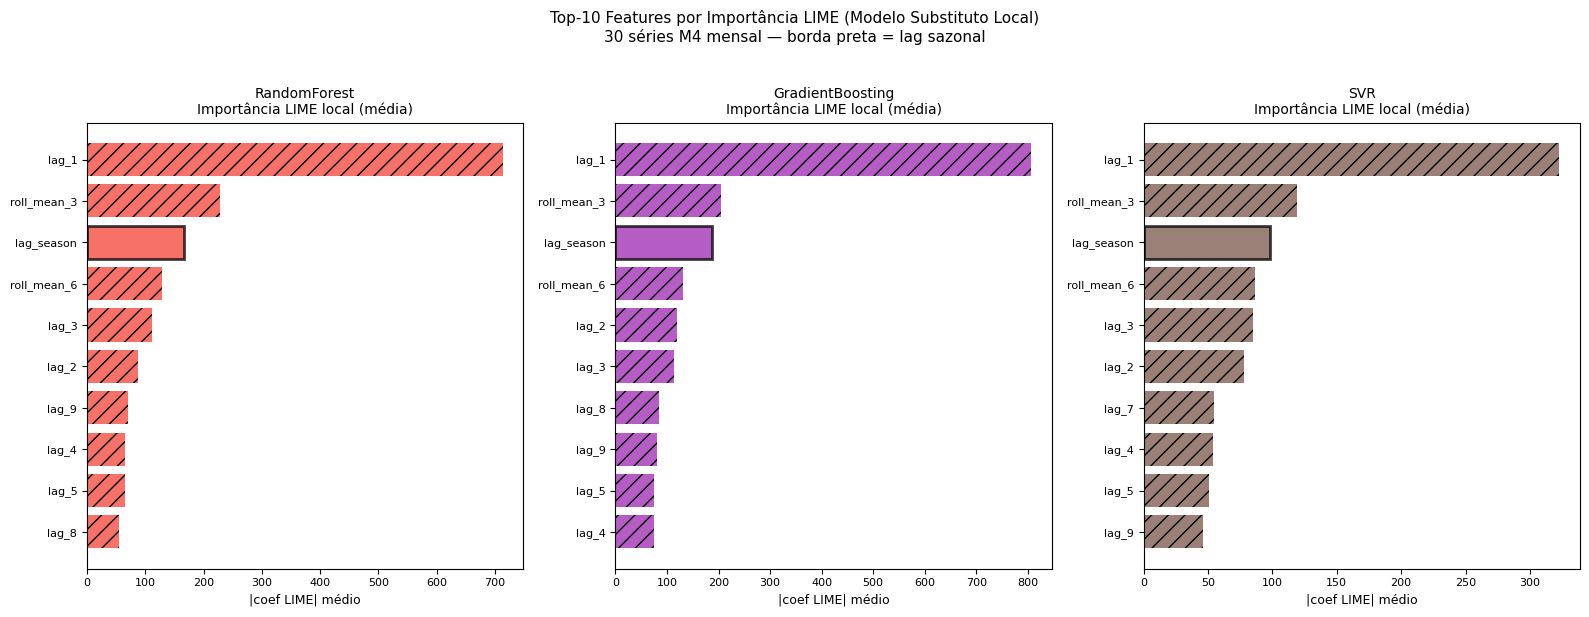

Fig 3 salva.


In [9]:
# ── Fig 3: Importância LIME global por modelo ─────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for ax, model_name in zip(axes, ['RandomForest', 'GradientBoosting', 'SVR']):
    sub      = df_lime[df_lime['modelo'] == model_name][FEATURE_NAMES]
    mean_imp = sub.mean().sort_values(ascending=False)
    top10    = mean_imp.head(10)

    color = ALGO_COLORS.get(model_name, 'coral')
    bars  = ax.barh(top10.index[::-1], top10.values[::-1],
                    color=color, alpha=0.75, hatch='//')

    for bar, lbl in zip(bars, top10.index[::-1]):
        if 'season' in lbl or lbl == 'lag_12':
            bar.set_edgecolor('black')
            bar.set_linewidth(2)
            bar.set_hatch('')

    ax.set_title(f'{model_name}\nImportância LIME local (média)', fontsize=10)
    ax.set_xlabel('|coef LIME| médio', fontsize=9)
    ax.tick_params(labelsize=8)

fig.suptitle('Top-10 Features por Importância LIME (Modelo Substituto Local)\n'
             f'{N_EXPL} séries M4 mensal — borda preta = lag sazonal',
             fontsize=11, y=1.02)
plt.tight_layout()
fig.savefig(EXPL_DIR / 'fig3_lime_global.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 3 salva.')

## 8. Comparação SHAP × LIME — Coerência entre métodos

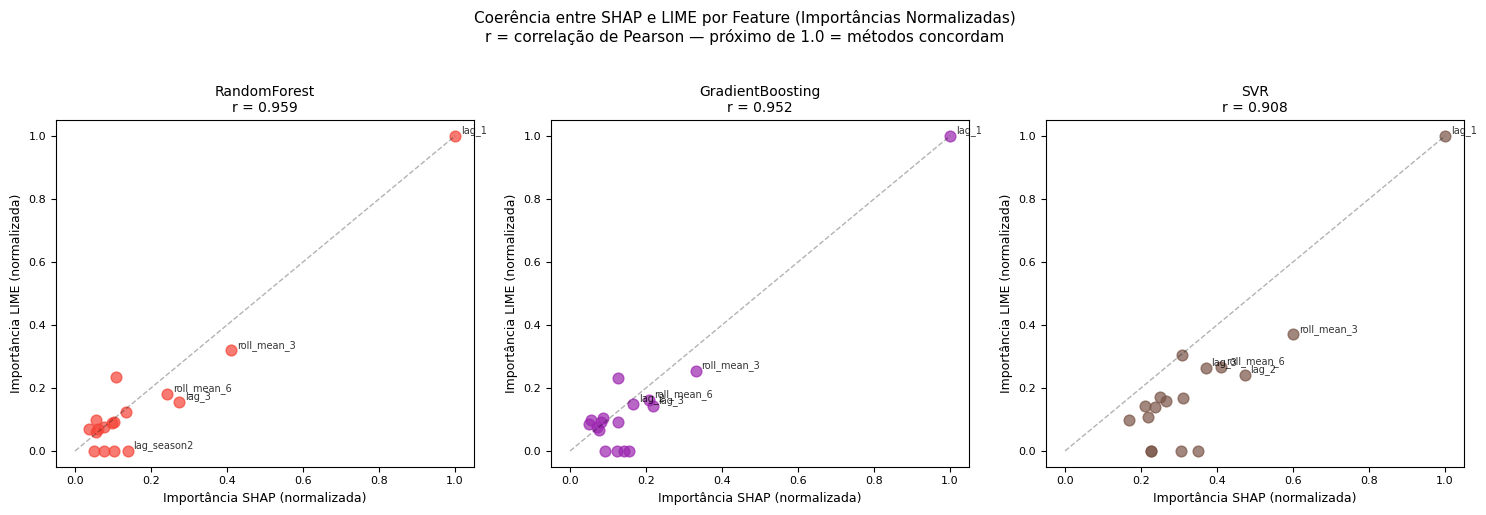


Correlação SHAP × LIME por modelo:
          modelo  correlacao_SHAP_LIME
    RandomForest                 0.959
GradientBoosting                 0.952
             SVR                 0.908


In [10]:
# ── Fig 4: Correlação SHAP × LIME por feature e modelo ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

corr_results = []

for ax, model_name in zip(axes, ['RandomForest', 'GradientBoosting', 'SVR']):
    shap_m = df_shap[df_shap['modelo'] == model_name][FEATURE_NAMES].mean()
    lime_m = df_lime[df_lime['modelo'] == model_name][FEATURE_NAMES].mean()

    # Normaliza para [0,1] para comparação justa
    shap_n = shap_m / (shap_m.max() + 1e-10)
    lime_n = lime_m / (lime_m.max() + 1e-10)

    corr = np.corrcoef(shap_n.values, lime_n.values)[0, 1]
    corr_results.append({'modelo': model_name, 'correlacao_SHAP_LIME': round(corr, 3)})

    color = ALGO_COLORS.get(model_name, 'gray')
    ax.scatter(shap_n.values, lime_n.values, color=color, alpha=0.7, s=60)

    # Anota features mais importantes
    top_feat = shap_n.sort_values(ascending=False).head(5).index
    for fn in top_feat:
        ax.annotate(fn, (shap_n[fn], lime_n[fn]),
                    fontsize=7, alpha=0.8,
                    xytext=(4, 2), textcoords='offset points')

    # Linha de referência (concordância perfeita)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, linewidth=1)
    ax.set_title(f'{model_name}\nr = {corr:.3f}', fontsize=10)
    ax.set_xlabel('Importância SHAP (normalizada)', fontsize=9)
    ax.set_ylabel('Importância LIME (normalizada)', fontsize=9)
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)
    ax.tick_params(labelsize=8)

fig.suptitle('Coerência entre SHAP e LIME por Feature (Importâncias Normalizadas)\n'
             'r = correlação de Pearson — próximo de 1.0 = métodos concordam',
             fontsize=11, y=1.02)
plt.tight_layout()
fig.savefig(EXPL_DIR / 'fig4_shap_vs_lime.png', dpi=150, bbox_inches='tight')
plt.show()

df_corr = pd.DataFrame(corr_results)
df_corr.to_csv(EXPL_DIR / 'correlacao_shap_lime.csv', index=False)
print('\nCorrelação SHAP × LIME por modelo:')
print(df_corr.to_string(index=False))

## 9. Estabilidade das explicações sob perturbação adversa

**Questão 3 da Seção 4.6:** as atribuições SHAP se mantêm estáveis quando os dados são perturbados?  
Compara importâncias SHAP da série limpa vs. série com ruído σ=30% (cenário mais adverso).

In [11]:
STAB_FILE = EXPL_DIR / 'shap_estabilidade_adversa.csv'

def perturb_noise(series, sigma_frac, rng):
    return series + rng.normal(0, np.std(series) * sigma_frac, size=len(series))

if STAB_FILE.exists():
    df_stab = pd.read_csv(STAB_FILE)
    print(f'Estabilidade carregada de cache: {STAB_FILE}')
else:
    print('Calculando estabilidade SHAP sob perturbação (ruído σ=30%)...')
    rng_pert = np.random.default_rng(SEED)
    stab_rows = []

    for i, s in enumerate(expl_series):
        s_pert = perturb_noise(s, sigma_frac=0.30, rng=rng_pert)

        fitted_clean = train_models_for_series(s)
        fitted_pert  = train_models_for_series(s_pert)

        if fitted_clean is None or fitted_pert is None:
            continue

        for model_name in ['RandomForest', 'GradientBoosting', 'SVR']:
            imp_clean = compute_shap(fitted_clean[model_name], model_name)
            imp_pert  = compute_shap(fitted_pert[model_name],  model_name)

            # Correlação de Spearman entre rankings das features
            from scipy.stats import spearmanr
            if not (np.all(np.isnan(imp_clean)) or np.all(np.isnan(imp_pert))):
                r, _ = spearmanr(imp_clean, imp_pert)
            else:
                r = np.nan

            row = {'serie': i, 'modelo': model_name, 'spearman_r': r}
            for j, fn in enumerate(FEATURE_NAMES):
                row[f'shap_clean_{fn}'] = imp_clean[j] if j < len(imp_clean) else np.nan
                row[f'shap_pert_{fn}']  = imp_pert[j]  if j < len(imp_pert)  else np.nan
            stab_rows.append(row)

        if (i + 1) % 10 == 0:
            print(f'  Estabilidade: série {i+1}/{N_EXPL}')

    df_stab = pd.DataFrame(stab_rows)
    df_stab.to_csv(STAB_FILE, index=False)
    print(f'✓ Estabilidade salva em {STAB_FILE}')

# Resumo por modelo
stab_resumo = df_stab.groupby('modelo')['spearman_r'].agg(['mean','std','median']).round(3)
stab_resumo.columns = ['r_médio', 'r_std', 'r_mediana']
print('\nEstabilidade SHAP (Spearman) — limpo vs. ruído σ=30%:')
print(stab_resumo.to_string())
stab_resumo.to_csv(EXPL_DIR / 'resumo_estabilidade_shap.csv')

Calculando estabilidade SHAP sob perturbação (ruído σ=30%)...


100%|██████████| 30/30 [00:00<00:00, 41.80it/s]


  Estabilidade: série 10/30


100%|██████████| 30/30 [00:00<00:00, 46.99it/s]


  Estabilidade: série 20/30


100%|██████████| 30/30 [00:00<00:00, 37.10it/s]


  Estabilidade: série 30/30
✓ Estabilidade salva em ..\results\explicabilidade\shap_estabilidade_adversa.csv

Estabilidade SHAP (Spearman) — limpo vs. ruído σ=30%:
                  r_médio  r_std  r_mediana
modelo                                     
GradientBoosting    0.384  0.193      0.344
RandomForest        0.521  0.192      0.572
SVR                 0.527  0.235      0.520


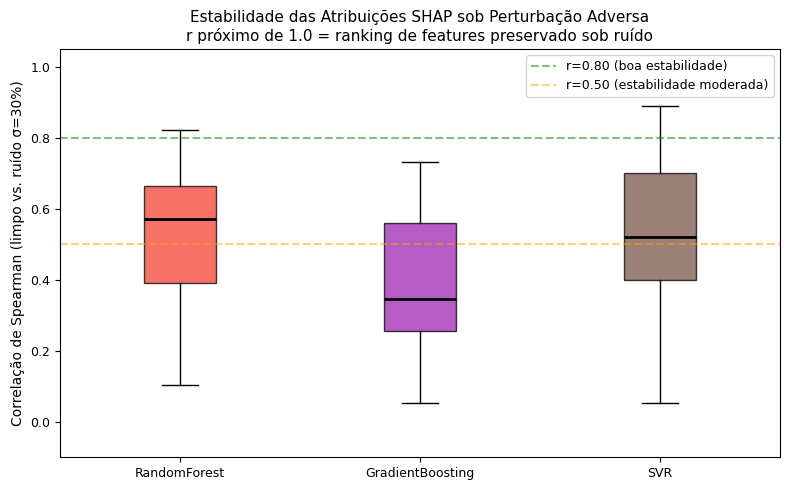

Fig 5 salva.


In [12]:
# ── Fig 5: Estabilidade SHAP — distribuição de Spearman por modelo ────────────
fig, ax = plt.subplots(figsize=(8, 5))

modelos_ord = ['RandomForest', 'GradientBoosting', 'SVR']
data_plot   = [df_stab[df_stab['modelo'] == m]['spearman_r'].dropna().values
               for m in modelos_ord]
colors      = [ALGO_COLORS[m] for m in modelos_ord]

bp = ax.boxplot(data_plot, labels=modelos_ord, patch_artist=True,
                medianprops=dict(color='black', linewidth=2))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.axhline(0.8, color='green', linestyle='--', alpha=0.5, label='r=0.80 (boa estabilidade)')
ax.axhline(0.5, color='orange', linestyle='--', alpha=0.5, label='r=0.50 (estabilidade moderada)')
ax.set_ylabel('Correlação de Spearman (limpo vs. ruído σ=30%)', fontsize=10)
ax.set_title('Estabilidade das Atribuições SHAP sob Perturbação Adversa\n'
             'r próximo de 1.0 = ranking de features preservado sob ruído',
             fontsize=11)
ax.legend(fontsize=9)
ax.set_ylim(-0.1, 1.05)
ax.tick_params(labelsize=9)

plt.tight_layout()
fig.savefig(EXPL_DIR / 'fig5_estabilidade_shap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 5 salva.')

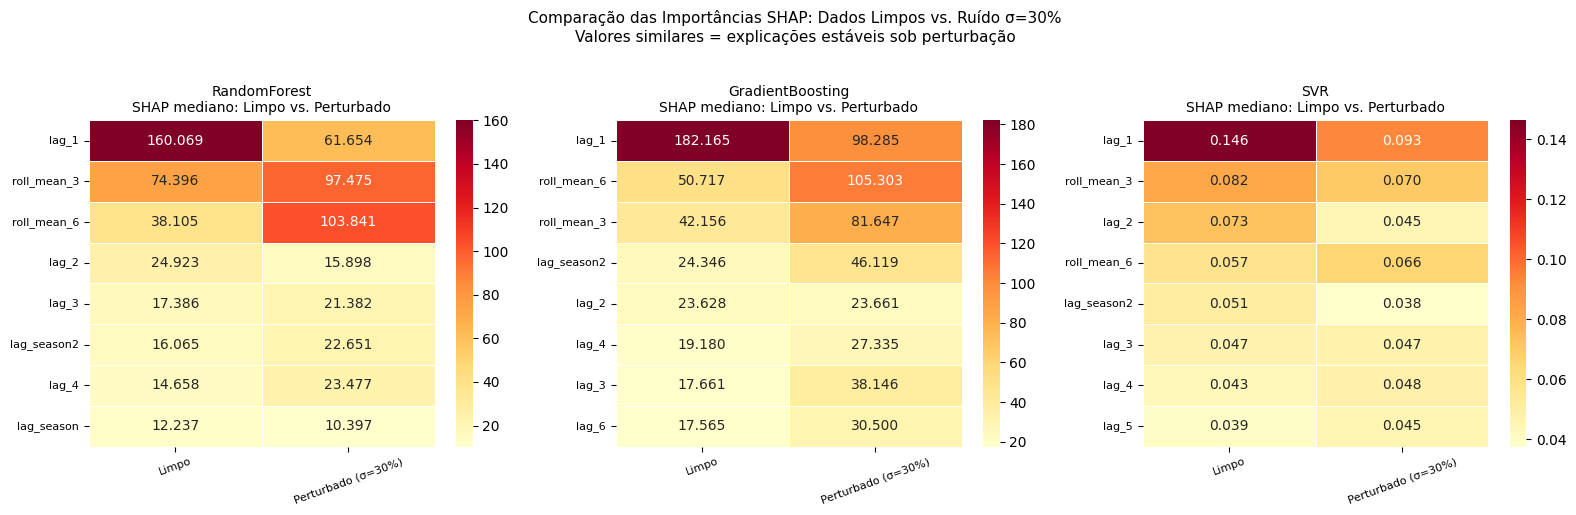

Fig 6 salva.


In [13]:
# ── Fig 6: Heatmap comparativo SHAP clean vs. pert (top-8 features, mediana) ──
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, model_name in zip(axes, modelos_ord):
    sub = df_stab[df_stab['modelo'] == model_name]

    clean_cols = [f'shap_clean_{fn}' for fn in FEATURE_NAMES]
    pert_cols  = [f'shap_pert_{fn}'  for fn in FEATURE_NAMES]

    clean_med = sub[clean_cols].median().values
    pert_med  = sub[pert_cols].median().values

    # Seleciona top-8 por importância limpa
    top8_idx  = np.argsort(clean_med)[::-1][:8]
    top8_feat = [FEATURE_NAMES[i] for i in top8_idx]

    matrix = pd.DataFrame(
        {'Limpo': clean_med[top8_idx], 'Perturbado (σ=30%)': pert_med[top8_idx]},
        index=top8_feat
    )

    sns.heatmap(matrix, annot=True, fmt='.3f', cmap='YlOrRd',
                ax=ax, cbar=True, linewidths=0.5)
    ax.set_title(f'{model_name}\nSHAP mediano: Limpo vs. Perturbado', fontsize=10)
    ax.tick_params(axis='x', rotation=20, labelsize=8)
    ax.tick_params(axis='y', rotation=0,  labelsize=8)

fig.suptitle('Comparação das Importâncias SHAP: Dados Limpos vs. Ruído σ=30%\n'
             'Valores similares = explicações estáveis sob perturbação',
             fontsize=11, y=1.02)
plt.tight_layout()
fig.savefig(EXPL_DIR / 'fig6_shap_clean_vs_pert.png', dpi=150, bbox_inches='tight')
plt.show()
print('Fig 6 salva.')

## 10. Tabela-resumo de explicabilidade (para a dissertação)

In [14]:
# Feature mais importante por método e modelo
resumo_expl = []
for model_name in ['RandomForest', 'GradientBoosting', 'SVR']:
    # SHAP
    shap_m   = df_shap[df_shap['modelo'] == model_name][FEATURE_NAMES].mean()
    top_shap = shap_m.idxmax()
    top2_shap = shap_m.sort_values(ascending=False).index[:3].tolist()

    # LIME
    lime_m   = df_lime[df_lime['modelo'] == model_name][FEATURE_NAMES].mean()
    top_lime = lime_m.idxmax()
    top2_lime = lime_m.sort_values(ascending=False).index[:3].tolist()

    # Estabilidade
    r_med = df_stab[df_stab['modelo'] == model_name]['spearman_r'].median()

    # Concordância SHAP × LIME
    corr_val = df_corr[df_corr['modelo'] == model_name]['correlacao_SHAP_LIME'].values
    corr_val = corr_val[0] if len(corr_val) > 0 else np.nan

    resumo_expl.append({
        'Modelo'              : model_name,
        'Top-1 SHAP'          : top_shap,
        'Top-3 SHAP'          : ', '.join(top2_shap),
        'Top-1 LIME'          : top_lime,
        'Top-3 LIME'          : ', '.join(top2_lime),
        'Concordância SHAP×LIME (r)': round(corr_val, 3),
        'Estabilidade Spearman (mediana)': round(r_med, 3),
    })

df_expl_resumo = pd.DataFrame(resumo_expl).set_index('Modelo')
print('Tabela-resumo de explicabilidade:')
print(df_expl_resumo.to_string())

df_expl_resumo.to_csv(EXPL_DIR / 'tabela_resumo_explicabilidade.csv')
print(f'\nSalvo em {EXPL_DIR / "tabela_resumo_explicabilidade.csv"}')

Tabela-resumo de explicabilidade:
                 Top-1 SHAP                 Top-3 SHAP Top-1 LIME                      Top-3 LIME  Concordância SHAP×LIME (r)  Estabilidade Spearman (mediana)
Modelo                                                                                                                                                        
RandomForest          lag_1  lag_1, roll_mean_3, lag_3      lag_1  lag_1, roll_mean_3, lag_season                       0.959                            0.572
GradientBoosting      lag_1  lag_1, roll_mean_3, lag_3      lag_1  lag_1, roll_mean_3, lag_season                       0.952                            0.344
SVR                   lag_1  lag_1, roll_mean_3, lag_2      lag_1  lag_1, roll_mean_3, lag_season                       0.908                            0.520

Salvo em ..\results\explicabilidade\tabela_resumo_explicabilidade.csv


## 11. Síntese interpretativa

In [15]:
print('=== SÍNTESE AUTOMÁTICA — EXPLICABILIDADE (OE4) ===')
print()
print('Questão 1 — Consistência entre janelas (variabilidade SHAP entre séries):')
for model_name in ['RandomForest', 'GradientBoosting', 'SVR']:
    sub = df_shap[df_shap['modelo'] == model_name][FEATURE_NAMES]
    cv  = (sub.std() / (sub.mean() + 1e-10)).mean()
    nivel = 'Alta' if cv < 0.5 else ('Moderada' if cv < 1.0 else 'Baixa')
    print(f'  {model_name}: CV médio = {cv:.2f} → consistência {nivel}')

print()
print('Questão 2 — Coerência com domínio (lag sazonal entre top-3 SHAP):')
for model_name in ['RandomForest', 'GradientBoosting', 'SVR']:
    shap_m = df_shap[df_shap['modelo'] == model_name][FEATURE_NAMES].mean()
    top3   = shap_m.sort_values(ascending=False).head(3).index.tolist()
    saz    = any('season' in f or f == 'lag_12' for f in top3)
    print(f'  {model_name}: top-3 = {top3} → lag sazonal no top-3: {"Sim" if saz else "Não"}')

print()
print('Questão 3 — Estabilidade sob perturbação adversa (Spearman mediano):')
for model_name in ['RandomForest', 'GradientBoosting', 'SVR']:
    r = df_stab[df_stab['modelo'] == model_name]['spearman_r'].median()
    nivel = 'Alta' if r >= 0.8 else ('Moderada' if r >= 0.5 else 'Baixa')
    print(f'  {model_name}: r = {r:.3f} → estabilidade {nivel}')

print()
print('Concordância SHAP × LIME:')
print(df_corr.to_string(index=False))

print()
print('Arquivos gerados em:', EXPL_DIR.resolve())
for f in sorted(EXPL_DIR.glob('*.csv')) + sorted(EXPL_DIR.glob('*.png')):
    print(' ', f.name)

=== SÍNTESE AUTOMÁTICA — EXPLICABILIDADE (OE4) ===

Questão 1 — Consistência entre janelas (variabilidade SHAP entre séries):
  RandomForest: CV médio = 1.75 → consistência Baixa
  GradientBoosting: CV médio = 1.61 → consistência Baixa
  SVR: CV médio = 0.51 → consistência Moderada

Questão 2 — Coerência com domínio (lag sazonal entre top-3 SHAP):
  RandomForest: top-3 = ['lag_1', 'roll_mean_3', 'lag_3'] → lag sazonal no top-3: Não
  GradientBoosting: top-3 = ['lag_1', 'roll_mean_3', 'lag_3'] → lag sazonal no top-3: Não
  SVR: top-3 = ['lag_1', 'roll_mean_3', 'lag_2'] → lag sazonal no top-3: Não

Questão 3 — Estabilidade sob perturbação adversa (Spearman mediano):
  RandomForest: r = 0.572 → estabilidade Moderada
  GradientBoosting: r = 0.344 → estabilidade Baixa
  SVR: r = 0.520 → estabilidade Moderada

Concordância SHAP × LIME:
          modelo  correlacao_SHAP_LIME
    RandomForest                 0.959
GradientBoosting                 0.952
             SVR                 0.908

A

---
## Registro de execução

In [16]:
import platform, sklearn, statsmodels

log = {
    'notebook'           : '09_explicabilidade.ipynb',
    'objetivo_especifico': 'OE4',
    'data_execucao'      : pd.Timestamp.now().isoformat(),
    'python'             : platform.python_version(),
    'sklearn'            : sklearn.__version__,
    'shap'               : shap.__version__,
    'seed'               : SEED,
    'n_series_piloto'    : N_SERIES,
    'n_series_expl'      : N_EXPL,
    'h'                  : H,
    'n_features'         : N_FEATURES,
    'feature_names'      : FEATURE_NAMES,
    'modelos_analisados' : ['RandomForest', 'GradientBoosting', 'SVR'],
    'metodos_xai'        : ['SHAP-TreeExplainer', 'SHAP-KernelExplainer', 'LIME'],
    'perturbacao_estabilidade': 'ruido_sigma_30pct',
    'referencia_dissertacao'  : 'Secao 4.6 — Analise de explicabilidade',
}

log_path = EXPL_DIR / 'execution_log.json'
with open(log_path, 'w', encoding='utf-8') as f:
    json.dump(log, f, indent=2, ensure_ascii=False, default=str)

print(json.dumps(log, indent=2, ensure_ascii=False, default=str))
print(f'\nSalvo em {log_path}')

{
  "notebook": "09_explicabilidade.ipynb",
  "objetivo_especifico": "OE4",
  "data_execucao": "2026-05-25T10:04:58.278837",
  "python": "3.11.0",
  "sklearn": "1.8.0",
  "shap": "0.51.0",
  "seed": 42,
  "n_series_piloto": 200,
  "n_series_expl": 30,
  "h": 18,
  "n_features": 17,
  "feature_names": [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_4",
    "lag_5",
    "lag_6",
    "lag_7",
    "lag_8",
    "lag_9",
    "lag_10",
    "lag_11",
    "lag_12",
    "roll_mean_3",
    "roll_std_3",
    "roll_mean_6",
    "lag_season",
    "lag_season2"
  ],
  "modelos_analisados": [
    "RandomForest",
    "GradientBoosting",
    "SVR"
  ],
  "metodos_xai": [
    "SHAP-TreeExplainer",
    "SHAP-KernelExplainer",
    "LIME"
  ],
  "perturbacao_estabilidade": "ruido_sigma_30pct",
  "referencia_dissertacao": "Secao 4.6 — Analise de explicabilidade"
}

Salvo em ..\results\explicabilidade\execution_log.json
